# Ask Your Metrics

This notebook checks whether a small business-question interface can stay tied to approved definitions and inspected SQL. The data is synthetic, and there is no live model call.

## 1. Load the metric engine and source tables

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(project_root / 'src'))
from metric_engine import answer_question
from run_analysis import CASES


In [2]:
database_path = project_root / 'data' / 'metrics_demo.sqlite'
monthly = pd.read_csv(project_root / 'data' / 'subscription_monthly.csv')
monthly.head()

,customer_id,month,status,mrr,prior_mrr
0,C-0001,2025-01-01,inactive,0.0,0.0
1,C-0001,2025-02-01,inactive,0.0,0.0
2,C-0001,2025-03-01,inactive,0.0,0.0
3,C-0001,2025-04-01,inactive,0.0,0.0
4,C-0001,2025-05-01,inactive,0.0,0.0


## 2. Ask a supported question

In [3]:
mrr_answer = answer_question('What was MRR in June 2026?', database_path)
pd.DataFrame({
    'field': ['status', 'intent', 'interpretation', 'answer'],
    'value': [mrr_answer['status'], mrr_answer['intent'], mrr_answer['interpretation'], mrr_answer['answer']],
})

,field,value
0,status,answered
1,intent,mrr
2,interpretation,Calculate ending MRR for 2026-06.
3,answer,"Ending MRR was $249,283.27."


In [4]:
print(mrr_answer['sql'])
print('Parameters:', mrr_answer['parameters'])

SELECT ROUND(SUM(mrr), 2) AS ending_mrr
FROM subscription_monthly
WHERE month = ?
  AND status IN ('active', 'past_due')
Parameters: ['2026-06-01']


## 3. Check a grouped result

In [5]:
segment_answer = answer_question('Which segment had the highest MRR in June 2026?', database_path)
pd.DataFrame(segment_answer['rows'], columns=segment_answer['columns'])

,segment,ending_mrr
0,Enterprise,167009.50
1,Mid-market,57133.85
2,SMB,25139.92


## 4. Keep clarification and refusal visible

In [6]:
fallbacks = [
    answer_question('How is revenue doing?', database_path),
    answer_question('What was CAC in June 2026?', database_path),
]
pd.DataFrame([{
    'status': item['status'],
    'interpretation': item['interpretation'],
    'answer': item['answer'],
    'query_ran': item['sql'] is not None,
} for item in fallbacks])

,status,interpretation,answer,query_ran
0,clarification,The request needs a metric and time period bef...,"Please specify MRR, active customers, churn, N...",False
1,unsupported,This question is outside the approved metric d...,I could not map this to an approved metric.,False


## 5. Review the checked MRR series

In [7]:
series_answer = answer_question('Show monthly MRR for 2026', database_path)
series = pd.DataFrame(series_answer['rows'], columns=series_answer['columns'])
series

,month,ending_mrr
0,2026-01-01,231830.52
1,2026-02-01,246242.86
2,2026-03-01,252905.70
3,2026-04-01,255097.15
4,2026-05-01,256101.49
5,2026-06-01,249283.27
6,2026-07-01,250684.10
7,2026-08-01,251680.89
8,2026-09-01,242092.63
9,2026-10-01,244224.37


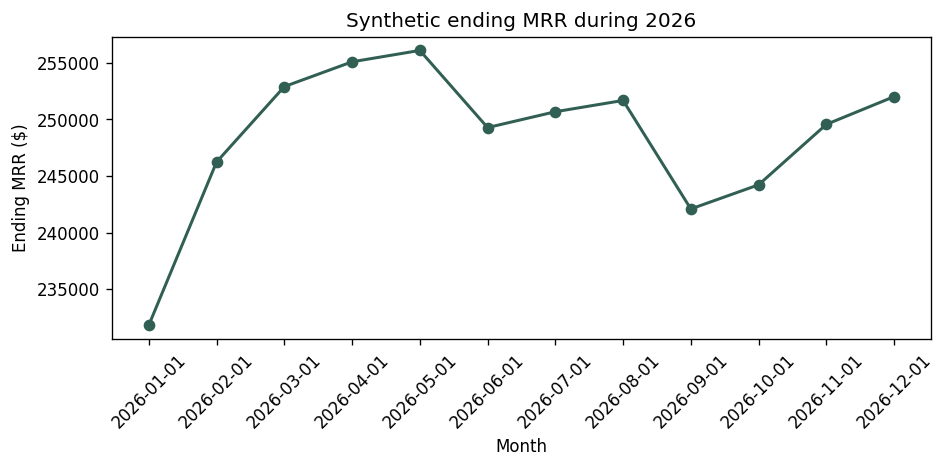

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(series['month'], series['ending_mrr'], color='#315f53', marker='o', linewidth=1.8)
ax.set(title='Synthetic ending MRR during 2026', xlabel='Month', ylabel='Ending MRR ($)')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

## 6. Interpretation

The project passed all 16 authored evaluation questions, including two clarification cases and four unsupported requests. That score describes this fixed test set only. The interface selects from approved templates; it is not an open-ended text-to-SQL system and not a live LLM integration.